# Лабораторная работа № 1. Регрессия

Цель — предсказать качество вина, сравнить модели по RMSE и MAE и разобрать их ошибки. Использую красное и белое вино вместе. Нужно получить RMSE < 0.70; Прогнозы не округляю.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer, PolynomialFeatures

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## Данные

Источник — [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality).

Объединяю оба CSV и добавляю `is_white`: 0 — красное, 1 — белое. Исходные 11 признаков описывают кислотность, сахар, хлориды, диоксид серы, плотность, pH, сульфаты и алкоголь. Цель `quality` — экспертная оценка качества. Ноутбук запускается из `lab1`, оба CSV лежат рядом.


In [2]:
red_data = pd.read_csv("winequality-red.csv", sep=";")
white_data = pd.read_csv("winequality-white.csv", sep=";")
red_data["is_white"] = 0
white_data["is_white"] = 1
data = pd.concat([red_data, white_data], ignore_index=True)

print("Красных / белых вин:", len(red_data), "/", len(white_data))
print("Размер общей таблицы:", data.shape)
print("Пропусков:", data.isna().sum().sum())
print("Полных повторов строк:", data.duplicated().sum())
display(data.head())


Красных / белых вин: 1599 / 4898
Размер общей таблицы: (6497, 13)
Пропусков: 0
Полных повторов строк: 1177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_white
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


Получилось 6497 строк и 13 столбцов: 12 признаков и цель. Пропусков нет. 1177 повторных строк оставляю, поскольку их происхождение неизвестно. Они могут попасть в обучение и тест одновременно и сделать оценку более оптимистичной.


## Разбиение данных

Оставляю 80% строк для обучения и 20% для теста: 5197 и 1300 образцов. Большая часть нужна для обучения, а 1300 строк позволяют сравнить модели на отдельной выборке. Перемешивание убирает зависимость разбиения от порядка «красные, затем белые»; временного порядка в данных нет. `random_state=42` фиксирует результат. `quality` в признаки не включаю.

Выбор моделей и параметров провожу по пятичастной CV внутри train. Многократный выбор по тестовым ошибкам завышает оценку качества. Этот тест уже просматривался до доработки линейной модели, поэтому повторная оценка новой версии не полностью независима; разбиение ради метрик не меняю.


In [3]:
X = data.drop(columns="quality")
y = data["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (5197, 12) Test: (1300, 12)


## Исследование train

Проверяю диапазоны и масштабы признаков только на обучающей части.


In [4]:
display(X_train.describe().T)


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5197.0,7.203146,1.288267,3.80000,6.40000,7.0000,7.70000,15.60000
volatile acidity,5197.0,0.337220,0.162180,0.08000,0.23000,0.2900,0.40000,1.58000
citric acid,5197.0,0.320275,0.144684,0.00000,0.25000,0.3100,0.39000,1.23000
residual sugar,5197.0,5.471666,4.796583,0.60000,1.80000,3.0000,8.20000,65.80000
chlorides,5197.0,0.055824,0.034830,0.00900,0.03800,0.0470,0.06400,0.61100
free sulfur dioxide,5197.0,30.565326,17.439545,1.00000,17.00000,29.0000,41.00000,146.50000
total sulfur dioxide,5197.0,115.713392,56.141996,6.00000,78.00000,118.0000,156.00000,344.00000
density,5197.0,0.994691,0.003009,0.98711,0.99234,0.9949,0.99699,1.03898
pH,5197.0,3.216956,0.159628,2.74000,3.11000,3.2100,3.32000,4.01000
sulphates,5197.0,0.531024,0.148661,0.22000,0.43000,0.5100,0.60000,2.00000


Средний `total sulfur dioxide` около 115.71, `density` — 0.995: масштабы сильно различаются. Перед линейными моделями использую стандартизацию для сопоставимости коэффициентов и штрафа Ridge. У остаточного сахара третий квартиль 8.2, максимум 65.8. Необычные значения не удаляю без подтверждения ошибки измерения.


quality
3      24
4     173
5    1736
6    2239
7     864
8     157
9       4
Name: count, dtype: int64

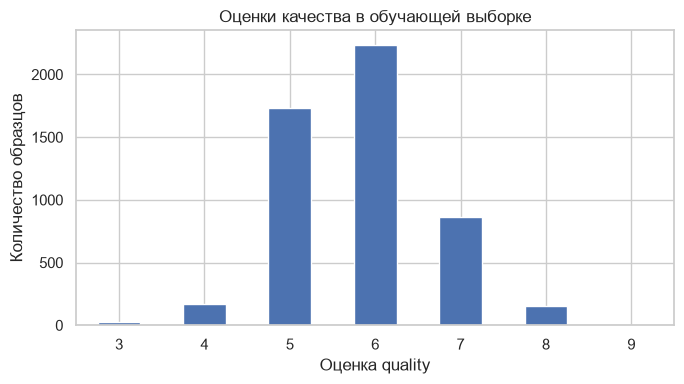

In [5]:
quality_counts = y_train.value_counts().sort_index()
display(quality_counts)

plt.figure(figsize=(7, 4))
quality_counts.plot(kind="bar", rot=0)
plt.xlabel("Оценка quality")
plt.ylabel("Количество образцов")
plt.title("Оценки качества в обучающей выборке")
plt.tight_layout()
plt.show()


Оценки 5 и 6 составляют около 76% train: 1736 и 2239 строк. Оценка 3 встречается 24 раза, 9 — только четыре. Мало примеров крайних оценок может затруднить их предсказание, поэтому позже проверю ошибки по группам quality.


alcohol                 0.448437
is_white                0.111031
citric acid             0.084433
free sulfur dioxide     0.060241
sulphates               0.046557
pH                      0.020651
residual sugar         -0.041898
total sulfur dioxide   -0.049577
fixed acidity          -0.065765
chlorides              -0.192250
volatile acidity       -0.263205
density                -0.301925
dtype: float64

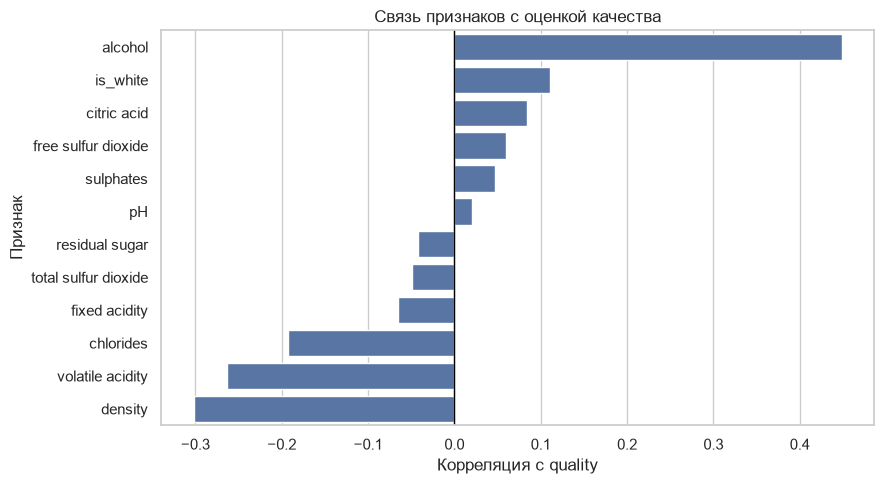

In [6]:
correlations = X_train.corrwith(y_train).sort_values(ascending=False)
display(correlations)

plt.figure(figsize=(9, 5))
sns.barplot(x=correlations, y=correlations.index)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Корреляция с quality")
plt.ylabel("Признак")
plt.title("Связь признаков с оценкой качества")
plt.tight_layout()
plt.show()


Наиболее заметные корреляции с качеством: `alcohol` +0.448, `density` −0.302 и `volatile acidity` −0.263. Например, более высокий алкоголь в этих данных связан с более высокой оценкой. Корреляции посчитаны на смеси двух типов вина и не доказывают причинность. Проверю эти связи на графиках.


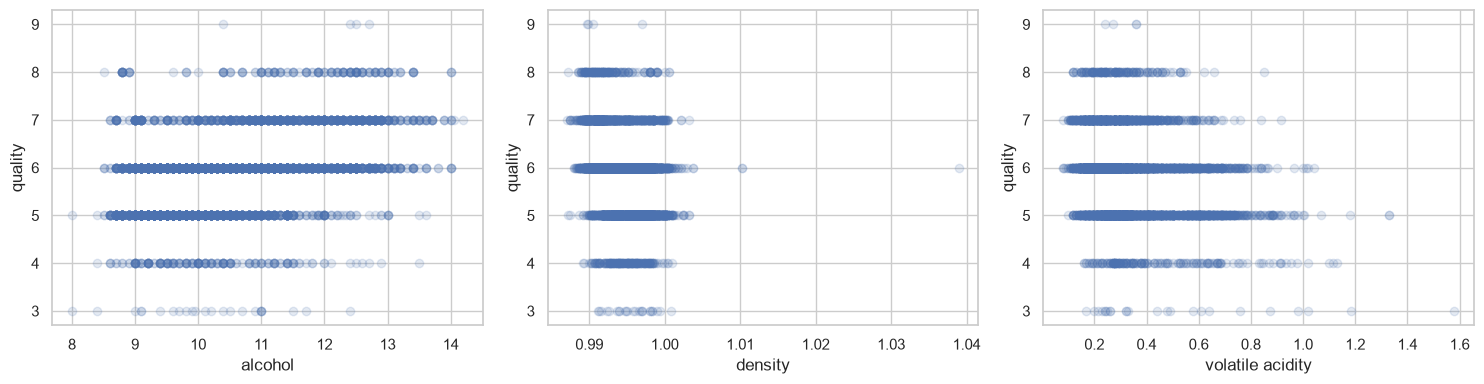

In [7]:
features = ["alcohol", "density", "volatile acidity"]

fig, axs = plt.subplots(figsize=(15, 4), ncols=3)
for i, feature in enumerate(features):
    axs[i].scatter(X_train[feature], y_train, alpha=0.15)
    axs[i].set_xlabel(feature)
    axs[i].set_ylabel("quality")
plt.tight_layout()
plt.show()


Тенденции видны, но при одинаковых значениях признаков оценки различаются. Одного показателя недостаточно. Сохраняю все 12 признаков: слабая отдельная корреляция не исключает пользы через взаимодействия или нелинейные зависимости.


## Метрики

MAE — средняя абсолютная ошибка: `mean(abs(y_true - y_pred))`. RMSE — корень из среднего квадрата ошибки: `sqrt(mean((y_true - y_pred)**2))`. Обе выражены в баллах quality, меньше — лучше. Основная метрика — RMSE.

Квадрат усиливает вклад больших промахов, поэтому при отдельных крупных ошибках RMSE заметно выше MAE. Для ошибок 0, 0, 3 получаются MAE = 1 и RMSE = √3 ≈ 1.73. Это средние показатели, а не величина ошибки каждого прогноза.

Все модели проверяю на одинаковых пяти частях train: четыре используются для обучения, одна для проверки, затем роли меняются. sklearn возвращает отрицательные скореры ошибок, поэтому при выводе меняю знак. Параметры преобразований обучаются внутри соответствующей обучающей части pipeline.


In [8]:
scoring = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
cv_results = []


## Baseline

Для всех вин предсказываю среднее обучающих оценок. Оно минимизирует сумму квадратов ошибок и RMSE; для MAE оптимальной константой была бы медиана. `DummyRegressor` пересчитывает среднее отдельно в каждом обучении CV, без ответов проверочной части.


In [9]:
baseline = DummyRegressor(strategy="mean")
baseline_scores = cross_validate(
    baseline, X_train, y_train, cv=5, scoring=scoring
)
cv_results.append({
    "Модель": "Baseline",
    "CV RMSE": -baseline_scores["test_rmse"].mean(),
    "Разброс RMSE": baseline_scores["test_rmse"].std(),
    "CV MAE": -baseline_scores["test_mae"].mean()
})
baseline.fit(X_train, y_train)
display(pd.DataFrame(cv_results[-1:]))

print(f"Константа на всём train: {y_train.mean():.4f}")


,Модель,CV RMSE,Разброс RMSE,CV MAE
0,Baseline,0.876606,0.013719,0.690982


Константа на всём train: 5.8145


Получилась константа 5.8145. CV RMSE ≈ 0.8766, MAE ≈ 0.6910. Это точка отсчёта: модель с признаками должна улучшить прогноз по сравнению с этим постоянным ответом. Тестовый baseline будет в общей итоговой таблице.


## Линейная регрессия

Использую StandardScaler и LinearRegression в одном pipeline. Масштабирование делает коэффициенты сопоставимыми, но само по себе не обязано улучшать обычную регрессию. При обучении scaler находит средние и стандартные отклонения только по обучающим строкам.


In [10]:
linear_model = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression())
])
linear_model_scores = cross_validate(
    linear_model, X_train, y_train, cv=5, scoring=scoring
)
cv_results.append({
    "Модель": "Linear Regression",
    "CV RMSE": -linear_model_scores["test_rmse"].mean(),
    "Разброс RMSE": linear_model_scores["test_rmse"].std(),
    "CV MAE": -linear_model_scores["test_mae"].mean()
})
linear_model.fit(X_train, y_train)
display(pd.DataFrame(cv_results[-1:]))


,Модель,CV RMSE,Разброс RMSE,CV MAE
0,Linear Regression,0.734005,0.009593,0.570062


density                -0.307099
residual sugar          0.301300
alcohol                 0.277079
volatile acidity       -0.244675
is_white               -0.143580
fixed acidity           0.118681
sulphates               0.113420
free sulfur dioxide     0.104242
total sulfur dioxide   -0.091639
pH                      0.084217
chlorides              -0.020291
citric acid            -0.014161
Name: Коэффициент, dtype: float64

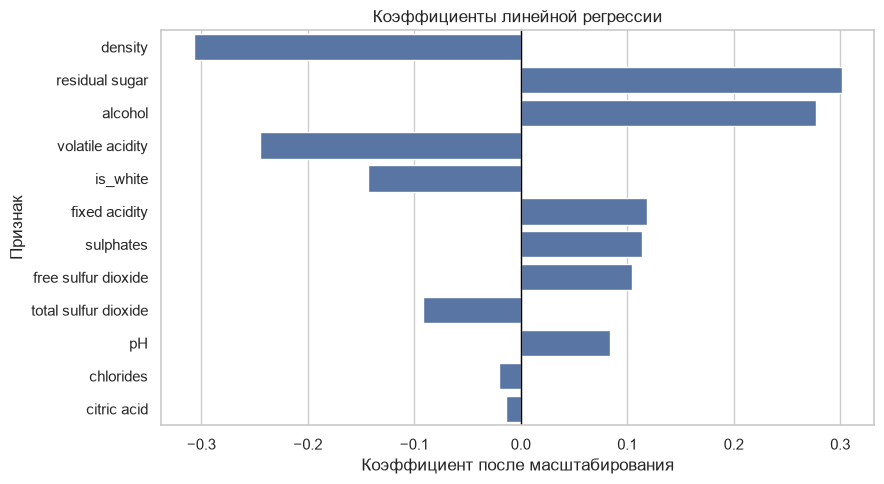

In [11]:
linear_weights = pd.Series(
    linear_model.named_steps["regression"].coef_,
    index=X_train.columns,
    name="Коэффициент"
).sort_values(key=abs, ascending=False)

display(linear_weights)

plt.figure(figsize=(9, 5))
sns.barplot(x=linear_weights, y=linear_weights.index)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Коэффициент после масштабирования")
plt.ylabel("Признак")
plt.title("Коэффициенты линейной регрессии")
plt.tight_layout()
plt.show()


CV RMSE ≈ 0.7340 и MAE ≈ 0.5701 ниже baseline, но порог 0.70 ещё не достигнут.

Крупнейшие по модулю коэффициенты: `density` −0.307, `residual sugar` +0.301, `alcohol` +0.277. Для химического признака коэффициент показывает изменение прогноза при росте на одно обучающее стандартное отклонение и фиксированных остальных признаках. Положительный знак повышает прогноз, отрицательный понижает.

У остаточного сахара отдельная корреляция была слабой и отрицательной, но регрессия учитывает другие признаки, поэтому знак отличается. Связанные признаки могут делать коэффициенты нестабильными.


### Доработка линейного решения: Йео — Джонсон и Ridge

Для порога добавляю Йео — Джонсона, полиномы степени 3 и Ridge. Йео — Джонсон стандартизует исходные признаки, второй scaler выравнивает масштабы полученных членов перед L2-штрафом. Ridge сдерживает большие коэффициенты, а `alpha` задаёт силу штрафа. Цель не преобразуется.

Проверяю четыре значения `alpha` по CV RMSE. Все преобразования находятся внутри pipeline и обучаются заново на каждой обучающей части.


In [12]:
ridge_pipeline = Pipeline([
    ("power", PowerTransformer(method="yeo-johnson")),
    ("polynomial", PolynomialFeatures(degree=3, include_bias=False)),
    ("scaling", StandardScaler()),
    ("regression", Ridge())
])
ridge_search = GridSearchCV(
    ridge_pipeline, {"regression__alpha": [10, 100, 300, 1000]},
    scoring=scoring, refit="rmse", cv=5
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_
display(pd.DataFrame({
    "alpha": ridge_search.cv_results_["param_regression__alpha"],
    "CV RMSE": -ridge_search.cv_results_["mean_test_rmse"],
    "CV MAE": -ridge_search.cv_results_["mean_test_mae"]
}))
print("Выбрано:", ridge_search.best_params_)

ridge_best_index = ridge_search.best_index_
cv_results.append({
    "Модель": "Ridge (YJ + полиномы)",
    "CV RMSE": -ridge_search.best_score_,
    "Разброс RMSE": ridge_search.cv_results_["std_test_rmse"][ridge_best_index],
    "CV MAE": -ridge_search.cv_results_["mean_test_mae"][ridge_best_index]
})


,alpha,CV RMSE,CV MAE
0,10,0.720156,0.552205
1,100,0.704270,0.543808
2,300,0.698967,0.541446
3,1000,0.699655,0.543628


Выбрано: {'regression__alpha': 300}


Выбран `alpha=300`: CV RMSE ≈ 0.6990, MAE ≈ 0.5414. После подбора лучший pipeline уже обучен на всём train. В нём 454 члена — преобразованные признаки, их степени и произведения. Модель линейна по коэффициентам, но нелинейна по исходным показателям. Показываю 15 крупнейших весов.


Число членов модели: 454


alcohol                            0.193729
chlorides                         -0.125321
free sulfur dioxide                0.114675
alcohol^2                          0.095223
free sulfur dioxide^2             -0.093288
alcohol is_white                   0.084067
free sulfur dioxide is_white       0.081246
volatile acidity                  -0.080771
total sulfur dioxide              -0.075737
alcohol is_white^2                 0.074299
total sulfur dioxide sulphates    -0.071757
volatile acidity alcohol           0.062236
fixed acidity chlorides alcohol   -0.057358
pH                                 0.056766
pH is_white                        0.054716
Name: Коэффициент, dtype: float64

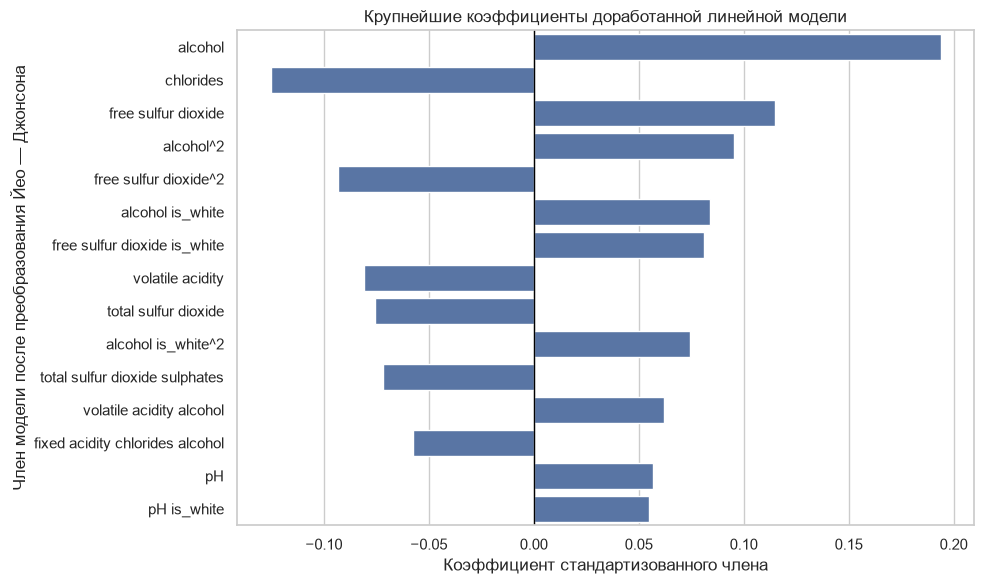

In [13]:
ridge_feature_names = ridge_model.named_steps["polynomial"].get_feature_names_out(X_train.columns)
ridge_weights = pd.Series(
    ridge_model.named_steps["regression"].coef_,
    index=ridge_feature_names,
    name="Коэффициент"
).sort_values(key=abs, ascending=False)
print("Число членов модели:", len(ridge_weights))
display(ridge_weights.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(x=ridge_weights.head(15), y=ridge_weights.head(15).index)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Коэффициент стандартизованного члена")
plt.ylabel("Член модели после преобразования Йео — Джонсона")
plt.title("Крупнейшие коэффициенты доработанной линейной модели")
plt.tight_layout()
plt.show()


Среди отдельных членов заметны алкоголь, хлориды и свободный диоксид серы. Имена относятся к значениям после Йео — Джонсона, а веса — к стандартизованным полиномиальным членам. Вес при `alcohol` не равен полному эффекту изменения алкоголя: одновременно меняются его степени и произведения. Это не независимые важности исходных показателей.


## Случайный лес

RandomForestRegressor усредняет деревья на случайных выборках строк с возвращением. Использую 100 деревьев без ограничения глубины и `random_state=42`, остальные настройки исходные. Лес учитывает нелинейные связи; масштабирование не требуется. Способ оценки остаётся тем же.


In [14]:
forest_model = RandomForestRegressor(random_state=RANDOM_STATE)
forest_model_scores = cross_validate(
    forest_model, X_train, y_train, cv=5, scoring=scoring
)
cv_results.append({
    "Модель": "Random Forest",
    "CV RMSE": -forest_model_scores["test_rmse"].mean(),
    "Разброс RMSE": forest_model_scores["test_rmse"].std(),
    "CV MAE": -forest_model_scores["test_mae"].mean()
})
forest_model.fit(X_train, y_train)
display(pd.DataFrame(cv_results[-1:]))


,Модель,CV RMSE,Разброс RMSE,CV MAE
0,Random Forest,0.618456,0.020241,0.444931


alcohol                 0.254585
volatile acidity        0.127507
free sulfur dioxide     0.089717
sulphates               0.078344
total sulfur dioxide    0.071939
residual sugar          0.070934
pH                      0.068788
chlorides               0.064446
density                 0.058684
citric acid             0.058301
fixed acidity           0.055866
is_white                0.000888
Name: Важность, dtype: float64

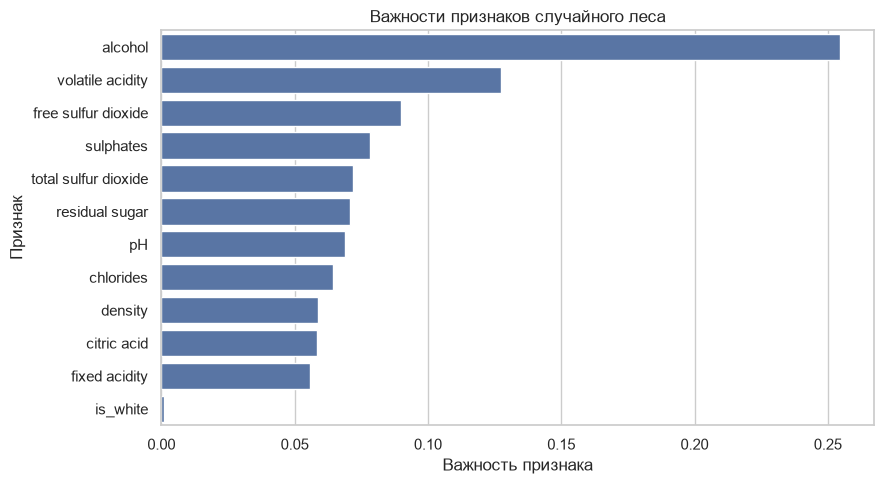

In [15]:
forest_importances = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns,
    name="Важность"
).sort_values(ascending=False)

display(forest_importances)

plt.figure(figsize=(9, 5))
sns.barplot(x=forest_importances, y=forest_importances.index)
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Важности признаков случайного леса")
plt.tight_layout()
plt.show()


CV RMSE ≈ 0.6185, MAE ≈ 0.4449 — ниже, чем у обоих линейных вариантов. Деревьям могут помогать нелинейные связи и сочетания показателей, которые исходная линейная модель описывает хуже.

Важности показывают вклад признаков в улучшение разбиений на обучении, но не направление влияния. Лидируют `alcohol` (0.255), `volatile acidity` (0.128), `free sulfur dioxide` (0.090). Первые два заметны и в корреляциях, третий может использоваться в нелинейных связях. С обычной регрессией совпадает алкоголь, а плотность и сахар у неё выражены сильнее.


## Градиентный бустинг

GradientBoostingRegressor строит деревья последовательно, исправляя остатки предыдущего прогноза. Использую 100 деревьев глубины до 3, `learning_rate=0.1` и `random_state=42`. Остальные настройки исходные. Масштабирование не требуется.


In [16]:
boosting_model = GradientBoostingRegressor(random_state=RANDOM_STATE)
boosting_model_scores = cross_validate(
    boosting_model, X_train, y_train, cv=5, scoring=scoring
)
cv_results.append({
    "Модель": "Gradient Boosting",
    "CV RMSE": -boosting_model_scores["test_rmse"].mean(),
    "Разброс RMSE": boosting_model_scores["test_rmse"].std(),
    "CV MAE": -boosting_model_scores["test_mae"].mean()
})
boosting_model.fit(X_train, y_train)
display(pd.DataFrame(cv_results[-1:]))


,Модель,CV RMSE,Разброс RMSE,CV MAE
0,Gradient Boosting,0.68634,0.016021,0.532067


alcohol                 0.456073
volatile acidity        0.181419
free sulfur dioxide     0.098402
sulphates               0.057764
residual sugar          0.047441
total sulfur dioxide    0.035221
pH                      0.030099
citric acid             0.028602
chlorides               0.024833
density                 0.020361
fixed acidity           0.018221
is_white                0.001562
Name: Важность, dtype: float64

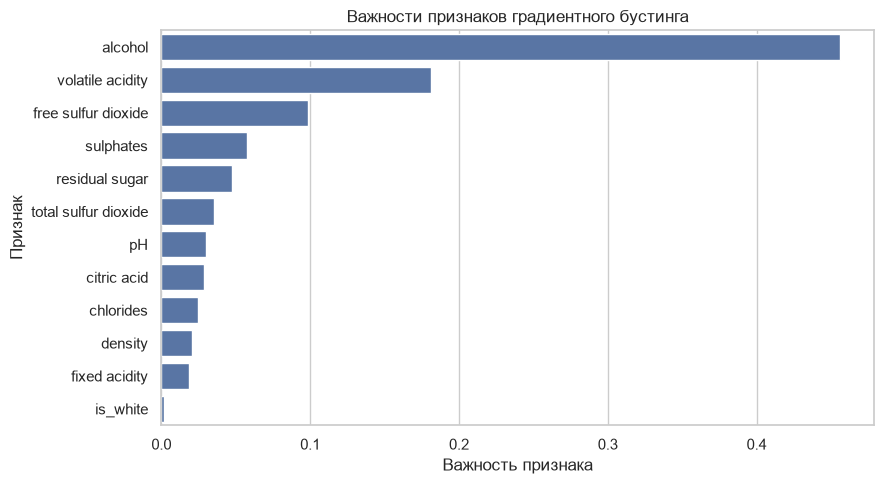

In [17]:
boosting_importances = pd.Series(
    boosting_model.feature_importances_,
    index=X_train.columns,
    name="Важность"
).sort_values(ascending=False)

display(boosting_importances)

plt.figure(figsize=(9, 5))
sns.barplot(x=boosting_importances, y=boosting_importances.index)
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.title("Важности признаков градиентного бустинга")
plt.tight_layout()
plt.show()


CV RMSE ≈ 0.6863, MAE ≈ 0.5321. Бустинг лучше исходной регрессии и baseline, но уступает лесу. Важности выделяют ту же тройку: алкоголь (0.456), летучую кислотность (0.181), свободный диоксид серы (0.098). На неё приходится большая доля важности, чем у леса. Разный способ построения ансамблей даёт разное использование остальных признаков.

Ни важность, ни коэффициент не доказывают, что изменение показателя вызовет изменение качества. Они описывают модель в наблюдаемых данных; возможны связи между признаками и общие причины. Величины коэффициентов и важностей напрямую несопоставимы.


## Общее сравнение и тест

Сводная таблица содержит результаты одинаковой пятичастной CV. По минимальному среднему RMSE выбираю модель для анализа ошибок.


In [18]:
comparison_cv = pd.DataFrame(cv_results).sort_values("CV RMSE")
display(comparison_cv)
best_model_name = comparison_cv.iloc[0]["Модель"]
print("Выбор по CV:", best_model_name)

models = {
    "Baseline": baseline,
    "Linear Regression": linear_model,
    "Ridge (YJ + полиномы)": ridge_model,
    "Random Forest": forest_model,
    "Gradient Boosting": boosting_model
}


,Модель,CV RMSE,Разброс RMSE,CV MAE
3,Random Forest,0.618456,0.020241,0.444931
4,Gradient Boosting,0.686340,0.016021,0.532067
2,Ridge (YJ + полиномы),0.698967,0.018019,0.541446
1,Linear Regression,0.734005,0.009593,0.570062
0,Baseline,0.876606,0.013719,0.690982


Выбор по CV: Random Forest


Все модели улучшили baseline. Лучший CV RMSE у леса; его оставляю для разбора ошибок. Ridge выполнил ориентир для линейного решения, но не превзошёл ансамбли.

Пять решений обучены только на train и оцениваются на одних 1300 тестовых строках. Quality не преобразуется, прогнозы не округляются. Тест уже просматривался до доработки Ridge, поэтому повторный результат не полностью независим. Параметры после него не меняю.


In [19]:
test_results = []
test_predictions = {}
for name, model in models.items():
    predictions = model.predict(X_test)
    test_predictions[name] = predictions
    test_results.append({
        "Модель": name,
        "Test RMSE": root_mean_squared_error(y_test, predictions),
        "Test MAE": mean_absolute_error(y_test, predictions)
    })
comparison_test = pd.DataFrame(test_results)
display(comparison_test)
best_test_pred = test_predictions[best_model_name]


,Модель,Test RMSE,Test MAE
0,Baseline,0.859605,0.669097
1,Linear Regression,0.735689,0.564413
2,Ridge (YJ + полиномы),0.684903,0.533854
3,Random Forest,0.608227,0.436754
4,Gradient Boosting,0.678413,0.532242


Все модели с признаками улучшили обе ошибки baseline. Обычная LinearRegression дала RMSE ≈ 0.7357, Ridge — 0.6849 и MAE ≈ 0.5339. Требование к линейному семейству выполнил регуляризованный вариант с расширенными признаками.

Лучший результат у леса: RMSE ≈ 0.6082, MAE ≈ 0.4368. У бустинга RMSE ≈ 0.6784, у baseline — 0.8596. Порядок моделей совпал с CV. На этих данных и исходных настройках усреднение деревьев в лесе оказалось лучше последовательного исправления ошибок в бустинге; это не общее преимущество алгоритма на любых данных.


## Ошибки выбранного леса

Ошибка определена как `прогноз − настоящая оценка`: положительная означает завышение. На втором графике диагональ соответствует точному прогнозу.


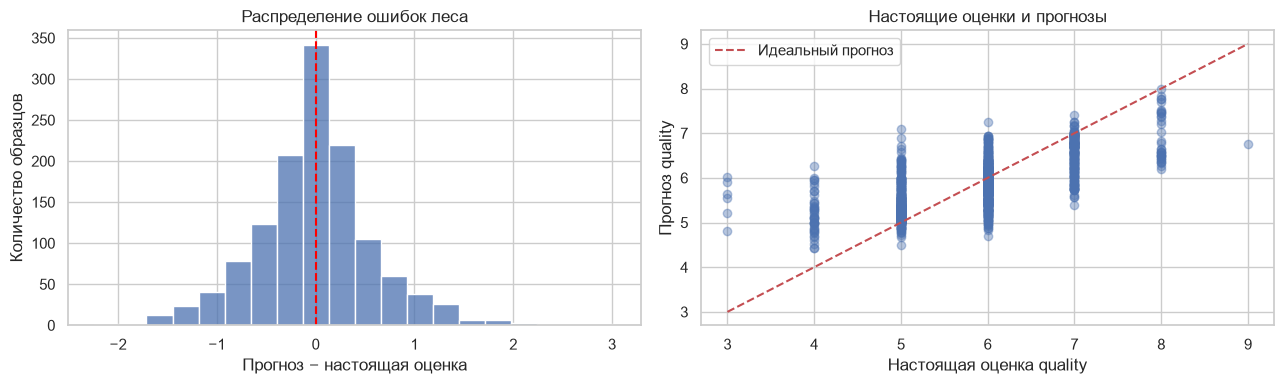

In [20]:
error_analysis = pd.DataFrame({
    "quality_true": y_test,
    "quality_pred": best_test_pred
})
error_analysis["error"] = error_analysis["quality_pred"] - error_analysis["quality_true"]
error_analysis["abs_error"] = error_analysis["error"].abs()

fig, axs = plt.subplots(ncols=2, figsize=(13, 4))

sns.histplot(error_analysis["error"], bins=20, ax=axs[0])
axs[0].axvline(0, color="red", linestyle="--")
axs[0].set_xlabel("Прогноз − настоящая оценка")
axs[0].set_ylabel("Количество образцов")
axs[0].set_title("Распределение ошибок леса")

axs[1].scatter(y_test, best_test_pred, alpha=0.4)
limits = [y_test.min(), y_test.max()]
axs[1].plot(limits, limits, "r--", label="Идеальный прогноз")
axs[1].set_xlabel("Настоящая оценка quality")
axs[1].set_ylabel("Прогноз quality")
axs[1].set_title("Настоящие оценки и прогнозы")
axs[1].legend()

plt.tight_layout()
plt.show()


В целом ошибки сосредоточены около нуля, но есть крупные промахи. Низкие оценки часто завышаются, высокие занижаются. Проверю различия по quality, учитывая размеры групп.


In [21]:
quality_results = []

for quality, group in error_analysis.groupby("quality_true"):
    quality_results.append({
        "quality": quality,
        "Объектов в train": (y_train == quality).sum(),
        "Объектов в test": len(group),
        "MAE": mean_absolute_error(group["quality_true"], group["quality_pred"]),
        "RMSE": root_mean_squared_error(group["quality_true"], group["quality_pred"]),
        "Средняя ошибка": group["error"].mean()
    })

errors_by_quality = pd.DataFrame(quality_results)
display(errors_by_quality)


,quality,Объектов в train,Объектов в test,MAE,RMSE,Средняя ошибка
0,3,24,6,2.525000,2.558414,2.525000
1,4,173,43,1.194186,1.273540,1.194186
2,5,1736,402,0.390721,0.543098,0.373060
3,6,2239,597,0.324338,0.422937,-0.114221
4,7,864,215,0.509256,0.644068,-0.494558
5,8,157,36,1.079167,1.205800,-1.079167
6,9,4,1,2.240000,2.240000,-2.240000


У оценок 6 и 5 MAE ≈ 0.324 и 0.391, это самые частые оценки. У оценки 3 MAE ≈ 2.525 на шести строках, у 8 — 1.079 на 36 строках. У оценки 9 один тестовый объект с ошибкой 2.24, а в train было всего четыре примера.

Редких оценок мало, а лес усредняет прогнозы — это может объяснять смещение к обычным значениям. Общая метрика скрывает разницу между группами; по единичным объектам нельзя делать устойчивые выводы.


### Крупные промахи

Выбираю пять наибольших ошибок и сопоставляю признаки со статистиками train из EDA. Индексы относятся к общей таблице.


In [22]:
worst_errors = error_analysis.sort_values("abs_error", ascending=False).head(5)
display(worst_errors)

review_features = [
    "alcohol", "volatile acidity", "free sulfur dioxide",
    "total sulfur dioxide", "fixed acidity", "pH"
]
display(X_test.loc[worst_errors.index, review_features])


,quality_true,quality_pred,error,abs_error
2339,3,6.03,3.03,3.03
6344,3,5.91,2.91,2.91
3649,3,5.63,2.63,2.63
3016,3,5.55,2.55,2.55
3715,4,6.26,2.26,2.26


,alcohol,volatile acidity,free sulfur dioxide,total sulfur dioxide,fixed acidity,pH
2339,12.6,0.39,5.0,19.0,6.9,3.31
6344,10.5,0.26,289.0,440.0,6.1,3.44
3649,9.7,0.23,15.0,123.0,11.8,2.93
3016,11.0,0.55,35.5,366.5,8.6,3.04
3715,11.7,0.20,19.0,68.0,6.8,3.14


**2339:** качество 3, прогноз 6.03. Алкоголь 12.6 выше третьего квартиля train (11.3), что могло способствовать высокому прогнозу. Примеров качества 3 в обучении всего 24.

**6344:** качество 3, прогноз 5.91. Свободный и общий диоксид серы равны 289 и 440, выше обучающих максимумов 146.5 и 344. Такое сочетание не встречалось в train и могло затруднить прогноз; это не доказывает ошибку измерений.

**3649:** качество 3, прогноз 5.63. Кислотность 11.8 выше третьего квартиля 7.7, pH=2.93 ниже первого квартиля 3.11. Возможные причины — редкая оценка и необычные характеристики.

Это предположения по отдельным строкам, а не доказанные причины. Модель после анализа не перенастраиваю.


## Выводы

На объединённых данных все модели улучшили baseline. Порог линейного решения достигнут с Йео — Джонсоном, полиномами и Ridge с выбранным по CV `alpha=300`: тестовые RMSE ≈ 0.6849, MAE ≈ 0.5339. Обычная LinearRegression порог не прошла. В целом лучшим остался лес с RMSE ≈ 0.6082, но на редких крайних оценках он работает хуже, чем на частых 5–6.

Ограничения: мало крайних оценок, повторы могли попасть в обе части, а тест был просмотрен до доработки линейной модели. CV после нескольких экспериментов тоже может быть оптимистичной. Полученные результаты относятся к этому разбиению. Версии пакетов сохранены в `requirements.txt`.
